# EDA: Reading Performance Dashboard

In [25]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import pyarrow, fastparquet
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
from statsmodels.compat import lzip
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.graphics.regressionplots import plot_leverage_resid2

In [11]:
read_df = pd.read_parquet('reading.parquet')
read_df.head()

,AGE_CATEGORY,GENDER,MAJOR,MINUTES_READING,MINUTES_BREAK,FOCUS_LEVEL,PAGES,CONTENT_LEVEL_ENUM,READING_GENRE,SOUND_VOLUME,...,LOCATION,WEATHER,MOOD,HUNGER,AROUSAL,MENTAL_IN_BREAK,COMPREHENSION_DEPTH,LINKING_TO_PREVIOUS_KNOWLEDGE,MENTAL_FATIGUE,INTERESTING_LEVEL
0,young_adult,male,student,80,10,2,8.0,2,technical_&_vocational,silent,...,home,clear,slightly_bad,slightly_hungry,slightly_low,neutral,good,some_connections,slightly_fatigued,neutral
1,young_adult,male,student,80,10,2,8.0,3,technical_&_vocational,silent,...,home,clear,slightly_bad,slightly_hungry,slightly_low,neutral,basic,some_connections,fresh,somewhat_interesting
2,young_adult,male,student,80,20,1,14.0,2,technical_&_vocational,silent,...,home,cloudy,slightly_bad,full,neutral,chaotic,basic,forced_linking,slightly_fatigued,neutral
3,young_adult,male,student,48,4,3,3.0,3,technical_&_vocational,silent,...,home,clear,neutral,full,high,chaotic,basic,forced_linking,normal,boring
4,young_adult,male,student,95,22,3,7.0,3,technical_&_vocational,silent,...,home,clear,neutral,satisfied,slightly_high,very_chaotic,basic,forced_linking,slightly_fatigued,extremely_boring


In [15]:
read_df.dtypes

AGE_CATEGORY                         str
GENDER                               str
MAJOR                                str
MINUTES_READING                    int64
MINUTES_BREAK                      int64
FOCUS_LEVEL                        int64
PAGES                            float64
CONTENT_LEVEL_ENUM                 int64
READING_GENRE                        str
SOUND_VOLUME                         str
DEVICE                               str
LOCATION                             str
WEATHER                              str
MOOD                                 str
HUNGER                               str
AROUSAL                              str
MENTAL_IN_BREAK                      str
COMPREHENSION_DEPTH                  str
LINKING_TO_PREVIOUS_KNOWLEDGE        str
MENTAL_FATIGUE                       str
INTERESTING_LEVEL                    str
dtype: object

In [9]:
read_df.isna().sum()

AGE_CATEGORY                     0
GENDER                           0
MAJOR                            0
MINUTES_READING                  0
MINUTES_BREAK                    0
FOCUS_LEVEL                      0
PAGES                            0
CONTENT_LEVEL_ENUM               0
READING_GENRE                    0
SOUND_VOLUME                     0
DEVICE                           0
LOCATION                         0
WEATHER                          0
MOOD                             0
HUNGER                           0
AROUSAL                          0
MENTAL_IN_BREAK                  0
COMPREHENSION_DEPTH              0
LINKING_TO_PREVIOUS_KNOWLEDGE    0
MENTAL_FATIGUE                   0
INTERESTING_LEVEL                0
dtype: int64

,MINUTES_READING,MINUTES_BREAK,FOCUS_LEVEL,PAGES,CONTENT_LEVEL_ENUM
MINUTES_READING,1.00,0.77,0.21,0.53,0.19
MINUTES_BREAK,0.77,1.00,0.09,0.24,0.19
FOCUS_LEVEL,0.21,0.09,1.00,0.09,0.22
PAGES,0.53,0.24,0.09,1.00,-0.11
CONTENT_LEVEL_ENUM,0.19,0.19,0.22,-0.11,1.00


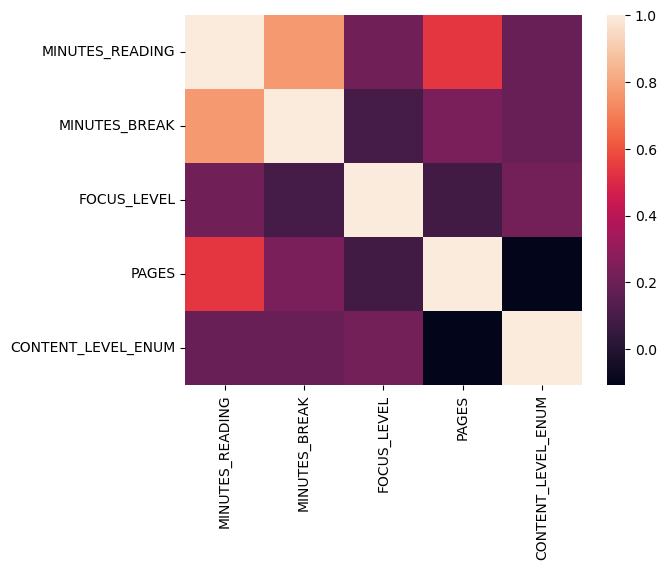

In [14]:
# heatmap
sns.heatmap(read_df.corr(numeric_only=True))
# correlation table
read_df.corr(numeric_only=True).round(2)

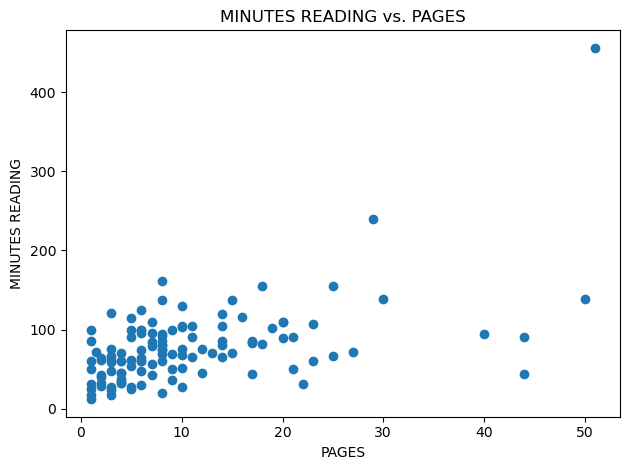

In [21]:
# scatter plot: FARE vs. DISTANCE  
fig, ax = plt.subplots()

ax.scatter(read_df['PAGES'], read_df['MINUTES_READING'])
ax.set_title('MINUTES READING vs. PAGES')
ax.set_xlabel('PAGES')
ax.set_ylabel('MINUTES READING')
fig.tight_layout()
plt.show()

In [26]:
model = smf.ols(formula='MINUTES_READING ~ PAGES', data=read_df)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:        MINUTES_READING   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.280
Method:                 Least Squares   F-statistic:                     46.45
Date:                Sat, 07 Feb 2026   Prob (F-statistic):           4.45e-10
Time:                        19:06:32   Log-Likelihood:                -609.74
No. Observations:                 118   AIC:                             1223.
Df Residuals:                     116   BIC:                             1229.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     48.9899      5.777      8.480      0.0

Notes on model: 
- With an r-squared value of 0.286 this tells us about 29% of the differences in reading time are explained by the number pages read 
- The p-value indicates the relationship between minutes read and pages read is strong 

In [10]:
read_df.to_csv('reading.csv', index=True, index_label="Index")